# TD combiné : Transformée de Hough & Homographie de points clés

Ce notebook regroupe deux TP de vision par ordinateur :
- **Partie 1** : détection de lignes et de cercles avec la transformée de Hough.
- **Partie 2** : détection/appariement de points clés et estimation d'une homographie pour superposer une image sur une scène.

---

## Partie 1 : Transformée de Hough : Expérimentation

Ce notebook vous permet d'expérimenter avec les transformées de Hough avant de les implémenter dans le jeu.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

%matplotlib inline

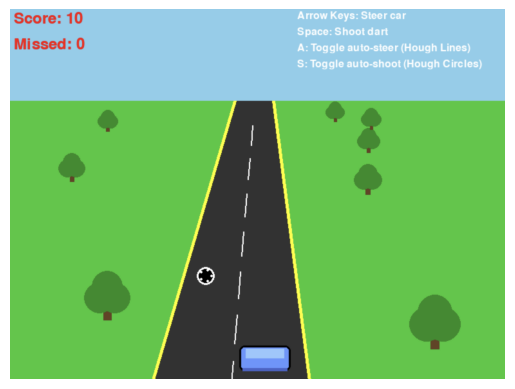

In [2]:
img = cv2.imread("screenshot.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.axis('off')
plt.show()

compute edges using Canny

### Line detection

use the cv2.HoughLines function to detect lines in the image. You can adjust the parameters to see how they affect the results.


In [ ]:
gray_lines = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
edges = cv2.Canny(gray_lines, 50, 150, apertureSize=3)

lines = cv2.HoughLines(edges, 1, np.pi / 180, 150)

disp_img = img.copy()

for rho, theta in lines[:, 0]:
    # display line
    a = math.cos(theta)
    b = math.sin(theta)
    x0 = a * rho
    y0 = b * rho
    pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
    pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
    cv2.line(disp_img, pt1, pt2, (0,0,255), 3, cv2.LINE_AA)

plt.imshow(disp_img)

vertical_lines = [
    (rho, theta)
    for rho, theta in lines[:, 0]
    if abs(math.cos(theta)) > 0.7
]


In [ ]:
# find the leftmost and rightmost lines
bottom_y = img.shape[0] - 1
left_line = min(
    vertical_lines,
    key=lambda line: (line[0] - bottom_y * math.sin(line[1])) / math.cos(line[1])
)
right_line = max(
    vertical_lines,
    key=lambda line: (line[0] - bottom_y * math.sin(line[1])) / math.cos(line[1])
)


In [ ]:
# find the intersection of the lines with the bottom of the image
bottom_y = img.shape[0] - 1
left_bottom = (
    int((left_line[0] - bottom_y * math.sin(left_line[1])) / math.cos(left_line[1])),
    bottom_y
)
right_bottom = (
    int((right_line[0] - bottom_y * math.sin(right_line[1])) / math.cos(right_line[1])),
    bottom_y
)

left_bottom, right_bottom


In [ ]:
disp_1 = img.copy()
for rho, theta in [left_line, right_line]:
    a = math.cos(theta)
    b = math.sin(theta)
    x0 = a * rho
    y0 = b * rho
    pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
    pt2 = (int(x0 - 2000*(-b)), int(y0 - 2000*(a)))
    cv2.line(disp_1, pt1, pt2, (255,0,0), 3, cv2.LINE_AA)
plt.imshow(disp_1)

### Circle detection

the cv2.HoughCircles function can be used to detect circles in an image. You can adjust the parameters to see how they affect the results.

Instead of taking a canny edge as input, this function works well with a blurred grayscale image. 

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
gray_blur = cv2.GaussianBlur(gray, (9, 9), 2)
plt.imshow(gray_blur, cmap='gray')


In [ ]:
circles = cv2.HoughCircles(
    gray_blur,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=30,
    param1=100,
    param2=30,
    minRadius=5,
    maxRadius=100
)

if circles is not None:
    circles = np.uint16(np.around(circles))
    disp_img = img.copy()
    for i in circles[0, :]:
        # draw the outer circle
        cv2.circle(disp_img, (i[0], i[1]), i[2], (0, 255, 0), 10)
        # draw the center of the circle
        cv2.circle(disp_img, (i[0], i[1]), 2, (0, 0, 255), 10)
    plt.imshow(disp_img)


In [ ]:
# keep only the circles that could be footballs
football_circles = [c for c in circles[0, :] if c[1] > 300]

disp_img = img.copy()
for i in football_circles:
    # draw the outer circle
    cv2.circle(disp_img, (i[0], i[1]), i[2], (0, 255, 0), 10)
    # draw the center of the circle
    cv2.circle(disp_img, (i[0], i[1]), 2, (0, 0, 255), 10)
plt.imshow(disp_img)
    

## Partie 2 : Appariement de points clés & Homographie : superposer un meme

Le but de ce TP est de créer un petit programme de réalité augmentée (2d pour la simplicité).

Pour cela, on va procéder à une **transformation homographique**.

<p align="center">
    <img src="https://miro.medium.com/v2/resize:fit:640/format:webp/1*M-z3caOhsdVWK36zY5AEdA.png">
</p>

Une transformation homographique est une opération qui peut "bouger" une image plane dans l'espace, en la faisant pivoter, translater, zoomer, etc. Les paramètres d'une transformation homograhique forment une matrice 3x3 qu'on appelle $H$, qu'il suffit d'appliquer aux coordonnées d'un point $x$ pour obtenir les nouvelles coordonnées $x'$ de ce point après transformation.

Objectif : détecter le flyer dans la scène, estimer une homographie et projeter l'image `meme.png` exactement sur la surface du flyer.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


flyer_path =  'flyer.jpeg'
scene_path =  'scene.jpg'
meme_path  =  'meme.png'

def show_rows(images, titles=None, cols=None, size=4):
    """Affiche plusieurs images côte à côte (ou en grille simple). Images BGR ou gray."""
    n = len(images)
    if cols is None:
        cols = n
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(size*cols, size*0.8*rows))
    for i, img in enumerate(images):
        plt.subplot(rows, cols, i+1)
        if img.ndim == 3 and img.shape[2] == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        elif img.ndim == 2:
            plt.imshow(img, cmap='gray')
        else:
            plt.imshow(img)
        if titles:
            plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Chargez les 3 images (flyer, scène, meme)
flyer  = cv2.imread(flyer_path, cv2.IMREAD_COLOR)
scene  = cv2.imread(scene_path, cv2.IMREAD_COLOR)
meme   = cv2.imread(meme_path, cv2.IMREAD_COLOR)
assert flyer is not None and scene is not None and meme is not None, 'Erreur: image introuvable.'

print('Shapes -> flyer:', flyer.shape, '| scene:', scene.shape, '| meme:', meme.shape)
show_rows([flyer, scene, cv2.rotate(meme, cv2.ROTATE_90_COUNTERCLOCKWISE)], ['Flyer (réf)', 'Scène (cible)', 'Meme'])


In [ ]:
flyer: np.ndarray
scene: np.ndarray
meme: np.ndarray

La cellule suivante vous permet de jouer avec les paramètres de la matrice $H$ pour comprendre l'effet de chaque paramètre. Familiarisez-vous avec les différentes transformations possibles en homographie.

In [ ]:
import ipywidgets as widgets
from ipywidgets import interact

meme_rotated = cv2.rotate(meme, cv2.ROTATE_90_COUNTERCLOCKWISE)

def interactive_homography(h00, h02, h11, h12, h20, h21):
    """
    Applies a manually defined homography to the meme and displays it.
    """
    # Construisez la matrice de l'homographie H à partir des valeurs des sliders
    H_manual = np.array([
        [h00, 0.0, h02],
        [0.0, h11, h12],
        [h20, h21, 1.0]
    ], dtype=np.float32)

    # Appliquez l'homographie H_manual au meme
    warped_meme_manual = cv2.warpPerspective(
        meme_rotated,
        H_manual,
        (meme_rotated.shape[1], meme_rotated.shape[0])
    )

    # Display the result
    show_rows([warped_meme_manual], ['Résultat avec H manuelle'], size=8)

# Create interactive sliders, starting from the identity matrix
interact(interactive_homography,
         h00=widgets.FloatSlider(value=1.0, min=-2.0, max=2.0, step=0.01, description='H[0,0] scale/rot'),
         h02=widgets.FloatSlider(value=0.0, min=-meme_rotated.shape[1], max=meme_rotated.shape[1], step=10, description='H[0,2] trans X'),
         h11=widgets.FloatSlider(value=1.0, min=-2.0, max=2.0, step=0.01, description='H[1,1] scale/rot'),
         h12=widgets.FloatSlider(value=0.0, min=-meme_rotated.shape[0], max=meme_rotated.shape[0], step=10, description='H[1,2] trans Y'),
         h20=widgets.FloatSlider(value=0.0, min=-0.001, max=0.001, step=0.00001, description='H[2,0] persp X', format='f'),
         h21=widgets.FloatSlider(value=0.0, min=-0.001, max=0.001, step=0.00001, description='H[2,1] persp Y', format='f')
);


### Estimation automatique des paramètres de $H$

Vous remarquerez qu'il semble possible de superposer l'image `meme.png` sur le flyer en jouant avec les paramètres de la matrice $H$. Cependant, dans une application réelle, on ne peut pas s'amuser à régler ces paramètres à la main. Il faut donc trouver un moyen d'estimer automatiquement la matrice $H$. 

OpenCV est capable d'estimer les paramètres de H à partir de 4 paires de points correspondants entre deux images. Par exemple, si vous connaissez les coordonnées des 4 coins d'une affiche au mur dans une photo, vous pouvez les faire correspondre aux 4 coins de l'image que vous voulez projeter sur cette affiche, et OpenCV sera capable d'estimer la matrice H qui "colle" votre nouvelle image sur l'affiche.

En utilisant les techniques de segmentation étudiées la semaine dernière par exemple, on peut identifier un objet dans la scène, en extraire ses contours, et en déduire les coordonnées de ses coins. Aujourd'hui cependant, on va utiliser une technique de reconnaissance d'objet plus puissante: la **détection et l'appariement de points clés**.


#### 1. Détection de points clés & descripteurs (ORB par défaut, SIFT optionnel)

On utilise ORB (rapide, libre). Vous pouvez activer SIFT si votre installation OpenCV le supporte. Pour rappel, SIFT est plus lent mais plus robuste que ORB.

si vous souhaitez utiliser SIFT, exécutez la cellule suivant pour installer la version d'OpenCV qui le supporte.

In [ ]:
!pip uninstall opencv-python -y
!pip install opencv-contrib-python

Détectez les points clés et extrayez leurs descripteurs dans les images `flyer` et `scene`, en utilisant le détecteur choisi (SIFT ou ORB selon `USE_SIFT`).

In [ ]:
USE_SIFT = False  # passer à True si disponible

if USE_SIFT:
    detector = cv2.SIFT_create()
    print('SIFT utilisé')
else:
    detector = cv2.ORB_create(nfeatures=5000)
    print('ORB utilisé')

kp_ref, des_ref = detector.detectAndCompute(flyer, None)
kp_scene, des_scene = detector.detectAndCompute(scene, None)
print(f'Points clés référence: {len(kp_ref)} | scène: {len(kp_scene)}')

flyer_kp_vis = cv2.drawKeypoints(flyer, kp_ref, None, color=(0,255,0), flags=cv2.DrawMatchesFlags_DRAW_RICH_KEYPOINTS)
scene_kp_vis = cv2.drawKeypoints(scene, kp_scene, None, color=(0,255,0), flags=cv2.DrawMatchesFlags_DRAW_RICH_KEYPOINTS)
show_rows([flyer_kp_vis, scene_kp_vis], ['KP Flyer', 'KP Scène'], size=6)


#### 2. Appariement des descripteurs (KNN + test de ratio)
Une fois les descripteurs extraits, il faut les apparier entre eux pour trouver quels points clés dans l'image de référence correspondent à quels points clés dans la scène.
OpenCV possède plusieurs fonctions pour faire cela, certaines sont plus adaptées à SIFT, d'autres à ORB.

On souhaite trouver les 2 meilleurs correspondances pour chaque descripteur, pour pouvoir appliquer le *test de ratio* de Lowe. Ce test permet d'éliminer les correspondances ambiguës: si les 2 meilleures correspondances sont très proches en terme de distance (par exemple, si la distance du meilleur match est 0.8 fois la distance du 2ème meilleur match), on considère que la correspondance n'est pas fiable et on l'élimine.


In [ ]:
ratio_thresh = 0.8

if USE_SIFT:
    index_params = dict(algorithm=1, trees=5)
    search_params = dict(checks=50)
    matcher = cv2.FlannBasedMatcher(index_params, search_params)
else:
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

raw_matches = matcher.knnMatch(des_ref, des_scene, k=2)
print('Nombre de paires brutes:', len(raw_matches))

good = []
for m, n in raw_matches:
    # Appliquer le test de ratio de Lowe
    if m.distance < ratio_thresh * n.distance:
        good.append(m)

print('Bons appariements après ratio test:', len(good))
# Tri pour visualisation stable
good = sorted(good, key=lambda m: m.distance)


#### 3. Visualisation : matchs bruts vs filtrés
On affiche un sous-ensemble pour garder de la lisibilité.

In [ ]:
visN = 1000
# Visualisez les correspondances brutes (raw_matches) et filtrées (good)
raw_vis = cv2.drawMatchesKnn(
    flyer, kp_ref, scene, kp_scene, raw_matches[:visN], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
filtered_vis = cv2.drawMatches(
    flyer, kp_ref, scene, kp_scene, good[:visN], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show_rows([raw_vis, filtered_vis], [f'Matchs bruts (N={visN})', f'Bons matchs (N={visN})'], size=6)


#### 4. Estimation de l'homographie

Maintenant qu'on a des paires de points correspondants entre les deux images, on peut estimer la matrice $H$ qui "colle" l'image du flyer sur la scène. Vous remarquerez que sur l'image ci-dessus, malgré notre test de ratio de Lowe, il reste encore parfois des correspondances erronées (des *outliers*). Pour gérer cela, on utilise l'algorithme RANSAC, qui va estimer la meilleure homographie possible en ignorant les correspondances erronées. Heureusement pour nous, OpenCV implémente déjà RANSAC dans sa fonction d'estimation d'homographie.


In [ ]:
# Construisez les tableaux de points src_pts et dst_pts à partir des bons appariements (good)
src_pts = np.float32([kp_ref[m.queryIdx].pt for m in good]).reshape(-1,1,2)
dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good]).reshape(-1,1,2)

H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
if H is None:
    raise RuntimeError('Estimation homographie échouée.')

inliers = int(mask.ravel().sum())
print('Matrice H:\n', H)
print(f'Inliers: {inliers}/{len(good)}')

inlier_matches = [good[i] for i in range(len(good)) if mask[i]]
vis_inliers = cv2.drawMatches(
    flyer, kp_ref, scene, kp_scene, inlier_matches[:1000], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

h_ref, w_ref = flyer.shape[:2]
ref_corners = np.float32([[0,0],[w_ref,0],[w_ref,h_ref],[0,h_ref]]).reshape(-1,1,2)
proj_corners = cv2.perspectiveTransform(ref_corners, H)
scene_poly = scene.copy()
cv2.polylines(scene_poly, [np.int32(proj_corners)], True, (0,255,0), 3)
show_rows([vis_inliers, scene_poly], ['Inliers (subset)', 'Projection quadrilatère'], size=6)


#### 5. Warp du meme sur le plan du flyer
On redimensionne le meme à la taille du flyer puis on applique l'homographie pour le projeter dans la scène.

In [ ]:
h_ref, w_ref = flyer.shape[:2]

meme_rgb = meme
meme_alpha = np.full(meme_rgb.shape[:2], 255, np.uint8)

meme_resized = cv2.resize(meme_rgb, (w_ref, h_ref))
alpha_resized = cv2.resize(meme_alpha, (w_ref, h_ref))

scene_h, scene_w = scene.shape[:2]
warped_meme = cv2.warpPerspective(meme_resized, H, (scene_w, scene_h))
warped_alpha = cv2.warpPerspective(alpha_resized, H, (scene_w, scene_h))
show_rows([warped_meme], ['Meme warpé'])


#### 6. Fusion & composition finale
On crée un masque depuis l'alpha (ou plein si absent) et on mélange avec la scène.

In [ ]:
alpha_f = warped_alpha.astype(np.float32)/255.0
alpha_3 = np.dstack([alpha_f]*3)
composite = scene.copy().astype(np.float32)
# Mélangez warped_meme et composite en utilisant alpha_3 comme poids
composite = warped_meme.astype(np.float32) * alpha_3 + composite * (1.0 - alpha_3)
composite = np.clip(composite,0,255).astype(np.uint8)
show_rows([composite], ['Composite final'], size=6)
